# 04 — Prediction intervals and error analysis

The Stage 3 point model (LightGBM, L1 loss), its features and the baselines are unchanged. This notebook adds:

1. **Two diagnostics**: whether `battalion` is an incident or a unit field, and travel time by dispatch order × priority.
2. **80% prediction intervals** from two LightGBM quantile models (α = 0.1 and α = 0.9), fit on train, then **conformalized (CQR)** on valid:
   - The conformity score is `s = max(lo − y, y − hi)`, and `q` is its ⌈(n+1)·0.8⌉/n empirical quantile. The final interval is `[lo − q, hi + q]`.
   - *Why:* valid is untouched by the quantile fits, so this gives finite-sample marginal coverage, **under exchangeability**.
   - A time split only approximates exchangeability (test is a later season), so coverage on test is measured, not assumed.
   - Valid also chose each quantile model's iteration count, a mild reuse.
3. **Error analysis on test**, as tables, plus one plot.

All logic lives in `src/`; this notebook only calls it.

In [1]:
import sys
from pathlib import Path

# The notebook runs from notebooks/; make the project root importable.
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from src import stage4, plots
from src.model import MODEL_NAME

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

In [2]:
r = stage4.run()  # ~4 min: re-runs Stage 3 (unchanged), then intervals and error analysis

## A. Diagnostics

In [3]:
r["call_fields"]  # battalion / station_area constant within calls? units spanning battalions?

{'calls_with_>1_row': 47214,
 'battalion_differs_within_call_%': 0.0,
 'station_area_differs_within_call_%': 0.0,
 'unit_ids_in_>1_battalion_%': 94.2}

In [4]:
r["seq_prio"]  # median travel_time_s and n by unit_sequence_in_call_dispatch x priority_group

n               median_s              
priority_group      2      3  other        2      3  other
unit_seq                                                  
1               30834  13813  13233    710.0  242.0  603.0
2                3661  28650   6257    533.0  388.0  393.0
3+                409   2179   1425    608.0  479.0  456.0

## D. 80% intervals

### Raw quantile intervals (valid and test)

In [5]:
print("iterations chosen on valid pinball loss:", r["q_iters"])
print("crossed pairs reordered: valid", r["crossed_valid"], "test", r["crossed_test"])
r["raw_interval"]

iterations chosen on valid pinball loss: {0.1: 934, 0.9: 610}
crossed pairs reordered: valid 0 test 0


,n,coverage,mean_width_s
split,,,
valid,8266,0.782603,633.541133
test,25252,0.777364,623.390462


### CQR margin from valid

In [6]:
print(f"n={r['cqr_n']:,}  level={r['cqr_level']:.5f}  q={r['cqr_q']:.1f} s")

n=8,266  level=0.80015  q=9.1 s


### Test: raw QR vs CQR vs B2 empirical interval (B2 refit on train+valid)

In [7]:
r["interval_test"]

,n,raw_QR_cov_%,raw_QR_width_s,CQR_cov_%,CQR_width_s,B2_cov_%,B2_width_s
segment,,,,,,,
ALL,25252,77.7,623.4,79.5,641.7,79.3,683.8
unit_type=MEDIC,19093,77.7,623.6,79.6,641.9,79.9,682.2
unit_type=PRIVATE,6159,77.8,622.6,79.4,640.9,77.7,688.9
priority_group=2,8988,77.9,860.2,79.0,878.4,78.9,904.9
priority_group=3,11329,77.6,379.9,80.0,398.2,79.6,448.8
priority_group=other,4935,77.7,751.1,79.5,769.4,79.5,820.8


## E. Error analysis on test (point model, CQR intervals)

In [8]:
for seg, table in r["errors_by"].items():
    print(f"by {seg}:")
    display(table)

by priority_group:


,n,MAE,P90AE,CQR_cov_%,CQR_width_s
priority_group,,,,,
2,8988,288.2,594.4,79.0,878.4
3,11329,141.7,286.2,80.0,398.2
other,4935,248.4,547.5,79.5,769.4


by unit_type:


,n,MAE,P90AE,CQR_cov_%,CQR_width_s
unit_type,,,,,
MEDIC,19093,213.6,487.3,79.6,641.9
PRIVATE,6159,218.1,502.3,79.4,640.9


by hour_band:


,n,MAE,P90AE,CQR_cov_%,CQR_width_s
hour_band,,,,,
00-06,4646,196.1,441.3,79.2,580.6
07-18,15252,226.0,519.4,79.5,666.8
19-23,5354,198.6,443.4,79.8,623.2


by spatial_block:


,n,MAE,P90AE,CQR_cov_%,CQR_width_s
spatial_block,,,,,
0,8168,206.6,478.2,80.5,629.2
1,1505,216.8,482.8,78.9,643.9
2,1144,216.6,478.5,78.1,635.7
3,1885,198.6,440.3,80.6,638.9
4,3363,221.3,503.9,78.9,631.1
5,2362,232.6,542.5,79.3,712.6
6,1066,237.7,503.4,78.4,697.3
7,1172,245.4,552.3,77.2,703.1
8,3360,199.6,454.7,79.7,589.9


In [9]:
print("station_area with >= 200 test rows: %d of %d" % r["station_eligible"])
display(r["station_best"])
display(r["station_worst"])

station_area with >= 200 test rows: 37 of 44


,n,MAE,P90AE,CQR_cov_%,CQR_width_s
station_area,,,,,
25,231,179.2,411.1,84.4,729.5
42,411,180.8,417.6,79.6,560.8
06,838,184.8,430.3,81.0,573.9
29,355,188.5,407.8,79.2,579.9
09,343,191.5,434.1,80.8,652.8


,n,MAE,P90AE,CQR_cov_%,CQR_width_s
station_area,,,,,
04,270,268.1,615.8,74.8,758.6
14,425,257.9,595.8,77.4,746.0
16,412,254.3,578.3,78.9,689.6
23,291,253.0,490.1,76.3,714.9
35,545,252.2,609.5,78.5,741.7


In [10]:
print(f"tail: actual > test 90th percentile ({r['tail_threshold']:.0f} s); signed error = actual - predicted")
r["tail"]

tail: actual > test 90th percentile (1094 s); signed error = actual - predicted


,n,MAE,mean_signed_error,under_predicted_%
model,,,,
LightGBM L1,2526,754.3,754.3,100.0
B2 station x priority_cat,2526,791.4,791.4,100.0


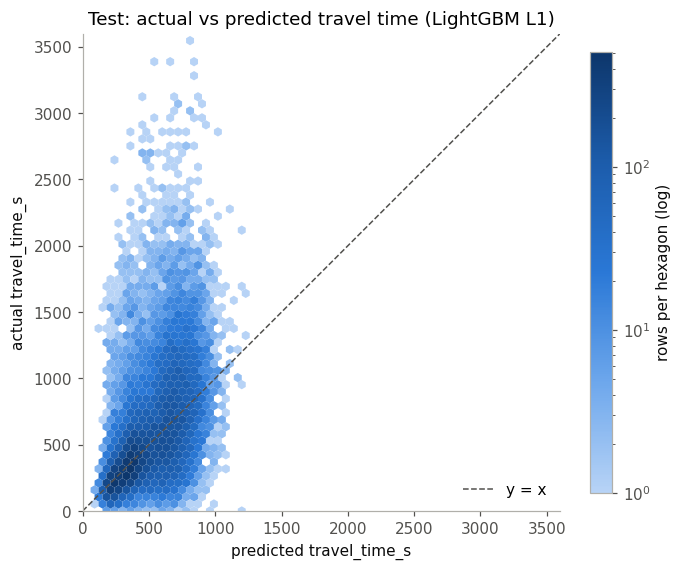

In [11]:
t = r["test_frame"]
plots.pred_vs_actual_hexbin(t["travel_time_s"], t["pred"]);